# LoDoPaB-CT split-conformal stress test (Colab small subset)

This notebook downloads the small LoDoPaB-derived subset mirrored by [GLIMPSE](https://github.com/swing-research/Glimpse): about 1,000 train images and 100 test images, rather than the full 55 GB archive. It resizes images to 128×128, simulates 50-view noisy sinograms, reconstructs them with FBP, trains a small CNN, then calibrates a maximum-pixel residual threshold.

The score is one maximum absolute pixel residual per image, so the target is simultaneous coverage of all pixels in a new image. The raw targets are from LoDoPaB-CT, but the measurements below are newly simulated with Gaussian sinogram noise; they are not the original official observations. The mirror does not document patient IDs, so this is an exploratory image-level stress test, not a patient-level coverage claim.

In Colab, choose Runtime → Change runtime type → GPU, then run all cells.

In [ ]:
%pip -q install huggingface_hub scikit-image
import math
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from skimage.transform import radon, iradon, resize
from huggingface_hub import snapshot_download

SEED, SIZE = 21, 128
N_TRAIN, N_CAL, N_TEST = 700, 300, 100
N_ANGLES, NOISE_SNR_DB = 50, 30.0
ALPHAS = [0.01, 0.05, 0.10, 0.20]
EPOCHS, BATCH_SIZE = 5, 32
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
rng = np.random.default_rng(SEED); torch.manual_seed(SEED)
print('Device:', device)

Device: cpu


In [ ]:
# Download only train/test data folders; skip the optional OOD images.
DATA_DIR = Path(snapshot_download(
    repo_id='AmirEhsan1995/lodopab-ct-glimpse', repo_type='dataset',
    allow_patterns=['train/**', 'test/**']))

def files_for(split):
    paths = sorted(p for p in DATA_DIR.rglob('*.npy') if split in p.parts)
    if not paths:
        raise FileNotFoundError(f'No .npy images for {split} under {DATA_DIR}; inspect mirror layout.')
    return paths

train_files, test_files = files_for('train'), files_for('test')
print('Images:', len(train_files), 'train,', len(test_files), 'test')
assert len(train_files) >= N_TRAIN + N_CAL and len(test_files) >= N_TEST
order = rng.permutation(len(train_files))
fit_files = [train_files[i] for i in order[:N_TRAIN]]
cal_files = [train_files[i] for i in order[N_TRAIN:N_TRAIN + N_CAL]]
test_order = rng.permutation(len(test_files))
heldout_files = [test_files[i] for i in test_order[:N_TEST]]

def load_targets(paths):
    out = []
    for p in paths:
        im = np.asarray(np.load(p), dtype=np.float32).squeeze()
        if im.ndim != 2: raise ValueError(f'Expected 2-D image, got {im.shape}: {p}')
        im = resize(im, (SIZE, SIZE), order=1, preserve_range=True, anti_aliasing=True)
        out.append(np.clip(im, 0, 1).astype(np.float32))
    return np.stack(out)

Y_fit, Y_cal, Y_test = map(load_targets, [fit_files, cal_files, heldout_files])
print('Targets:', Y_fit.shape, Y_cal.shape, Y_test.shape)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 1222 files:   0%|          | 0/1222 [00:00<?, ?it/s]

Images: 1111 train, 111 test
Targets: (700, 128, 128) (300, 128, 128) (100, 128, 128)


FBP 100/700
FBP 200/700
FBP 300/700
FBP 400/700
FBP 500/700
FBP 600/700
FBP 700/700
FBP 100/300
FBP 200/300
FBP 300/300
FBP 100/100


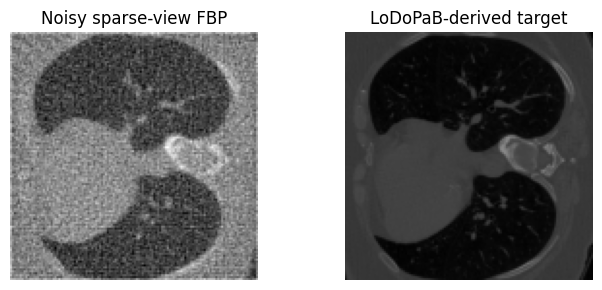

In [ ]:
# Simulate sparse-view measurements and reconstruct with filtered back projection.
angles = np.linspace(0, 180, N_ANGLES, endpoint=False)
def make_fbp_inputs(targets, seed):
    local_rng = np.random.default_rng(seed); result = []
    for i, im in enumerate(targets):
        sino = radon(im, theta=angles, circle=False).astype(np.float32)
        std = (10 ** (-NOISE_SNR_DB / 20)) * np.linalg.norm(sino) / np.sqrt(sino.size)
        noisy = sino + local_rng.normal(0, std, sino.shape).astype(np.float32)
        result.append(iradon(noisy, theta=angles, circle=False, output_size=SIZE).astype(np.float32))
        if (i + 1) % 100 == 0: print(f'FBP {i + 1}/{len(targets)}')
    return np.stack(result)
X_fit = make_fbp_inputs(Y_fit, SEED + 1)
X_cal = make_fbp_inputs(Y_cal, SEED + 2)
X_test = make_fbp_inputs(Y_test, SEED + 3)
fig, ax = plt.subplots(1, 2, figsize=(7, 3))
ax[0].imshow(X_fit[0], cmap='gray'); ax[0].set_title('Noisy sparse-view FBP')
ax[1].imshow(Y_fit[0], cmap='gray', vmin=0, vmax=1); ax[1].set_title('LoDoPaB-derived target')
for a in ax: a.axis('off')
plt.tight_layout()

In [ ]:
class SmallCNN(nn.Module):
    def __init__(self, width=32):
        super().__init__()
        self.net = nn.Sequential(nn.Conv2d(1,width,3,padding=1), nn.ReLU(),
            nn.Conv2d(width,width,3,padding=1), nn.ReLU(),
            nn.Conv2d(width,width,3,padding=1), nn.ReLU(),
            nn.Conv2d(width,1,3,padding=1))
    def forward(self, x): return x + self.net(x)

def tensor4(a): return torch.from_numpy(a).float().unsqueeze(1)
loader = DataLoader(TensorDataset(tensor4(X_fit), tensor4(Y_fit)),
                    batch_size=BATCH_SIZE, shuffle=True)
model = SmallCNN().to(device)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
for epoch in range(EPOCHS):
    model.train(); total = 0.0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        loss = F.mse_loss(model(x), y)
        opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
        total += loss.item() * len(x)
    print(f'Epoch {epoch+1}/{EPOCHS}: train MSE={total/len(loader.dataset):.6f}')

@torch.no_grad()
def predict(a):
    model.eval(); out=[]; x=tensor4(a)
    for i in range(0, len(x), BATCH_SIZE): out.append(model(x[i:i+BATCH_SIZE].to(device)).cpu())
    return torch.cat(out)
pred_cal, pred_test = predict(X_cal), predict(X_test)
# Clip centers to the known target range so the residual score exactly
# matches the intervals constructed below.
pred_cal = pred_cal.clamp(0, 1)
pred_test = pred_test.clamp(0, 1)

Epoch 1/5: train MSE=0.002692
Epoch 2/5: train MSE=0.000932
Epoch 3/5: train MSE=0.000651
Epoch 4/5: train MSE=0.000562
Epoch 5/5: train MSE=0.000505


alpha | q | whole-image test coverage | pixel coverage | mean width
0.01 | 0.3630 | 0.940 | 1.000 | 0.5278
0.05 | 0.3412 | 0.940 | 1.000 | 0.5058
0.10 | 0.3158 | 0.900 | 1.000 | 0.4800
0.20 | 0.2869 | 0.830 | 1.000 | 0.4502


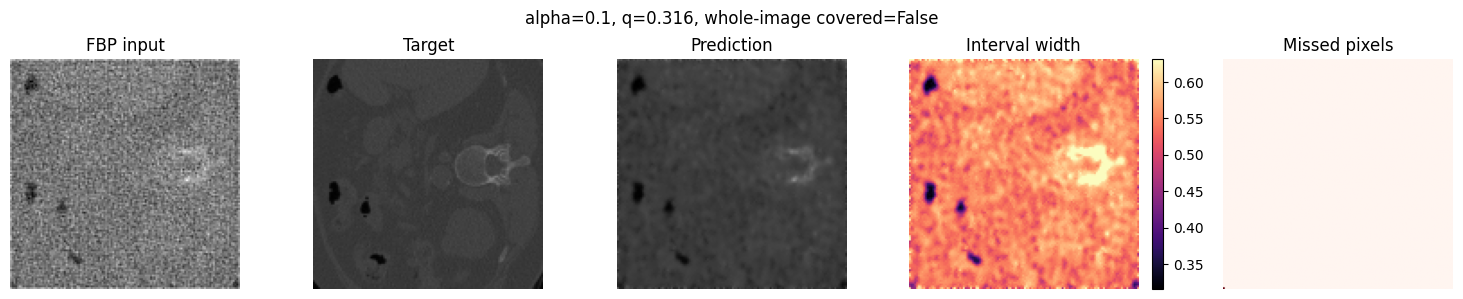

In [ ]:
# Split-conformal max-pixel score: one calibration score per image.
scores = (tensor4(Y_cal) - pred_cal).abs().flatten(1).amax(1).numpy()
def conformal_q(scores, alpha):
    n=len(scores); k=math.ceil((n+1)*(1-alpha))
    return float('inf') if k>n else float(np.partition(scores, k-1)[k-1])

print('alpha | q | whole-image test coverage | pixel coverage | mean width')
results={}
for alpha in ALPHAS:
    q=conformal_q(scores, alpha)
    lo=torch.clamp(pred_test-q, 0, 1); hi=torch.clamp(pred_test+q, 0, 1)
    inside=(tensor4(Y_test)>=lo) & (tensor4(Y_test)<=hi)
    image_cov=inside.flatten(1).all(1).float().mean().item()
    pixel_cov=inside.float().mean().item(); width=(hi-lo).mean().item()
    results[alpha]=(q,lo,hi)
    print(f'{alpha:.2f} | {q:.4f} | {image_cov:.3f} | {pixel_cov:.3f} | {width:.4f}')

# Visualize one untouched test image for alpha=0.10.
alpha=0.10; q,lo,hi=results[alpha]; i=0
target=Y_test[i]; center=pred_test[i,0].numpy()
miss=(target < lo[i,0].numpy()) | (target > hi[i,0].numpy())
fig,ax=plt.subplots(1,5,figsize=(15,3))
ax[0].imshow(X_test[i],cmap='gray'); ax[0].set_title('FBP input')
ax[1].imshow(target,cmap='gray',vmin=0,vmax=1); ax[1].set_title('Target')
ax[2].imshow(np.clip(center,0,1),cmap='gray',vmin=0,vmax=1); ax[2].set_title('Prediction')
im=ax[3].imshow((hi[i,0]-lo[i,0]).numpy(),cmap='magma'); ax[3].set_title('Interval width'); fig.colorbar(im,ax=ax[3],fraction=.046)
ax[4].imshow(miss,cmap='Reds'); ax[4].set_title('Missed pixels')
for a in ax: a.axis('off')
plt.suptitle(f'alpha={alpha}, q={q:.3f}, whole-image covered={not miss.any()}'); plt.tight_layout()

RCPS: n_opt=150, n_risk=150, delta=0.1, Hoeffding margin=0.0876
epsilon | selected radius | risk-split empirical | risk upper bound | test coverage | test mean width | status
0.01 | 0.360 | 0.027 | 0.114 | 0.940 | 0.5248 | not certified
0.05 | 0.360 | 0.027 | 0.114 | 0.940 | 0.5248 | not certified
0.10 | 0.360 | 0.027 | 0.114 | 0.940 | 0.5248 | not certified
0.20 | 0.310 | 0.133 | 0.221 | 0.900 | 0.4741 | not certified
Example test image: RCPS covered=False, split-conformal covered=False


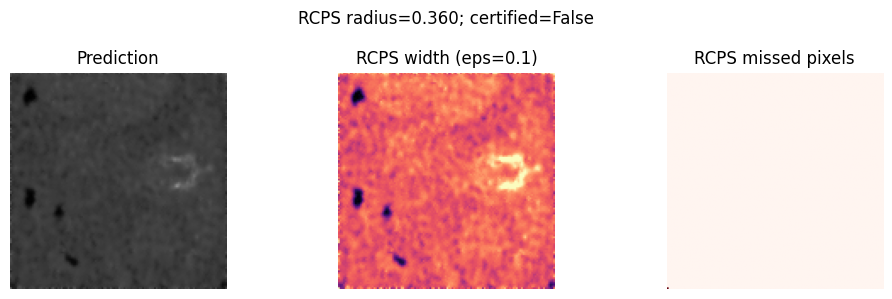

In [ ]:
# Scalar RCPS stress test. Use half of the calibration images to select a
# radius, and the other half once to certify its image-level miss risk.
# This is deliberately separate from split conformal above.
EPSILONS = [0.01, 0.05, 0.10, 0.20]
DELTA = 0.10
rcps_order = rng.permutation(len(scores))
n_opt = len(scores) // 2
scores_opt = scores[rcps_order[:n_opt]]
scores_risk = scores[rcps_order[n_opt:]]
n_risk = len(scores_risk)
# Fixed grid and Hoeffding margin are chosen without looking at risk-split labels.
LAMBDA_GRID = np.linspace(0.0, 2.0, 201)
hoeffding_margin = math.sqrt(math.log(1 / DELTA) / (2 * n_risk))
print(f'RCPS: n_opt={n_opt}, n_risk={n_risk}, delta={DELTA}, Hoeffding margin={hoeffding_margin:.4f}')
print('epsilon | selected radius | risk-split empirical | risk upper bound | test coverage | test mean width | status')
rcps_results = {}
for epsilon in EPSILONS:
    # Pick the narrowest radius whose optimization-split empirical risk leaves
    # room for the fixed Hoeffding margin. Selection does not use scores_risk.
    candidates = [lam for lam in LAMBDA_GRID
                  if np.mean(scores_opt > lam) <= max(0.0, epsilon - hoeffding_margin)]
    if not candidates:
        print(f'{epsilon:.2f} | -- | -- | >= {hoeffding_margin:.4f} | -- | -- | not certifiable with this bound/sample size')
        continue
    lam = float(candidates[0])
    risk_split_losses = (scores_risk > lam).astype(float)
    risk_hat = float(risk_split_losses.mean())
    risk_ucb = min(1.0, risk_hat + hoeffding_margin)
    certified = risk_ucb <= epsilon
    lo_rcps = torch.clamp(pred_test - lam, 0, 1)
    hi_rcps = torch.clamp(pred_test + lam, 0, 1)
    test_inside = (tensor4(Y_test) >= lo_rcps) & (tensor4(Y_test) <= hi_rcps)
    test_coverage = test_inside.flatten(1).all(1).float().mean().item()
    test_width = (hi_rcps - lo_rcps).mean().item()
    rcps_results[epsilon] = {'lambda': lam, 'risk_hat': risk_hat, 'risk_ucb': risk_ucb,
                           'certified': certified, 'lower': lo_rcps, 'upper': hi_rcps,
                           'test_coverage': test_coverage, 'test_width': test_width}
    status = 'certified' if certified else 'not certified'
    print(f'{epsilon:.2f} | {lam:.3f} | {risk_hat:.3f} | {risk_ucb:.3f} | {test_coverage:.3f} | {test_width:.4f} | {status}')

# At epsilon=0.10, compare the RCPS and split-conformal radii on the same test image.
epsilon_vis = 0.10
if epsilon_vis in rcps_results:
    rr = rcps_results[epsilon_vis]
    j = 0
    rcps_miss = (Y_test[j] < rr['lower'][j, 0].numpy()) | (Y_test[j] > rr['upper'][j, 0].numpy())
    print(f'Example test image: RCPS covered={not rcps_miss.any()}, split-conformal covered={not miss.any()}')
    fig, ax = plt.subplots(1, 3, figsize=(10, 3))
    ax[0].imshow(np.clip(pred_test[j, 0].numpy(), 0, 1), cmap='gray', vmin=0, vmax=1); ax[0].set_title('Prediction')
    ax[1].imshow((rr['upper'][j, 0] - rr['lower'][j, 0]).numpy(), cmap='magma'); ax[1].set_title(f'RCPS width (eps={epsilon_vis})')
    ax[2].imshow(rcps_miss, cmap='Reds'); ax[2].set_title('RCPS missed pixels')
    for a in ax: a.axis('off')
    plt.suptitle(f'RCPS radius={rr["lambda"]:.3f}; certified={rr["certified"]}'); plt.tight_layout()

## Reading the results

`whole-image test coverage` is the fraction of the 100 untouched test images for which every pixel fell inside the interval. `pixel coverage` is the aggregate fraction of pixels inside intervals. The formal split-conformal statement is marginal over exchangeable image units; the test estimate is noisy because it uses only 100 images.

This mirror does not expose patient IDs in its documented format. The image-level split therefore cannot rule out repeated images from the same patient across splits. Treat the result as a method/compute stress test, not as a patient-level medical claim. For a patient-level study, use data with patient metadata and split/group by patient. The subset is LoDoPaB-derived, but the low-dose inputs here are simulated with Gaussian noise, not the official Poisson-style observations.

### What the RCPS cell adds

The RCPS loss is the indicator that **any pixel** in an image is missed, matching the whole-image event used by the split-conformal score. RCPS uses half the 300 calibration images to choose a scalar radius and the other half to compute a one-sided Hoeffding upper bound with confidence parameter `delta=0.10`. For risk target `epsilon`, a result is labeled certified only if that bound is at most epsilon. At low epsilon, the bound can be too wide to certify; this is a valid outcome, not a failure of the notebook. The test coverage and width are empirical diagnostics and are not used to choose or certify the radius.

This is scalar RCPS, not K-RCPS. It controls the probability of missing at least one pixel in a new image; it does not optimize a separate width for each pixel or group.